# Import and Download Dependecies

In [1]:
!pip install transformers
!pip install datasets pyter3

In [2]:
import pandas as pd
from datasets import Dataset
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from torch import optim
from torch.nn import functional as F
from transformers import (
    AdamW,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
    get_cosine_schedule_with_warmup,
    get_constant_schedule_with_warmup
)
from tqdm import tqdm
from nltk.translate.bleu_score import corpus_bleu
import pyter
import string

# Constant

In [3]:
# Konfigurasi Model dan Data
MODEL_REPOSITORY = 'google/t5-v1_1-base'
SAVE_MODEL_PATH = 't5-v1_1_translation.pt'
MAX_SEQUENCE_LENGTH = 32
DATA_FILE_PATH = '/kaggle/input/parallel (1).xlsx'
TEST_SPLIT_FRACTION = 0.05

LANGUAGE_TOKEN_MAP = {
    'ind': '<ind>',
    'day': '<day>'
}

NUM_EPOCHS = 15
BATCH_SIZE = 16
PRINT_FREQUENCY = 200
CHECKPOINT_FREQUENCY = 1000
LEARNING_RATE = 1e-3

# Function Definition

## Data Preprocess and Generator

In [4]:
# Fungsi Pra-pemrosesan Teks
def preprocess_text(text):
    """
    Membersihkan dan memproses teks input.
    
    Args:
        text (str): Teks yang akan diproses.
    
    Returns:
        str: Teks yang telah dibersihkan dan diproses.
    """
    if isinstance(text, str):
        text = text.replace('-', ' ')  # Ganti tanda hubung dengan spasi
        text = text.lower()  # Ubah ke huruf kecil
        text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
        text = ' '.join(text.split())  # Hapus spasi ekstra
    else:
        text = ''
    return text

# Generator Data
def create_data_loader(dataset, language_token_map, tokenizer, batch_size=32):
    """
    Membuat generator data untuk memuat data dalam batch.
    
    Args:
        dataset (Dataset): Dataset Hugging Face.
        language_token_map (dict): Pemetaan token bahasa.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
        batch_size (int): Ukuran batch.
    
    Yields:
        tuple: Batch input IDs dan batch target IDs.
    """
    dataset = dataset.shuffle()
    for i in range(0, len(dataset), batch_size):
        raw_batch = dataset[i:i+batch_size]
        yield prepare_batch(raw_batch, language_token_map, tokenizer)

## Encode Input

In [5]:
# Encode Input Teks Sumber
def encode_source_text(text, target_language, tokenizer, seq_length=MAX_SEQUENCE_LENGTH,
                       language_token_map=LANGUAGE_TOKEN_MAP):
    """
    Mengkodekan teks sumber dengan menambahkan token bahasa target di depannya.
    
    Args:
        text (str): Teks sumber.
        target_language (str): Bahasa target.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
        seq_length (int, optional): Panjang urutan maksimum. Default adalah MAX_SEQUENCE_LENGTH.
        language_token_map (dict, optional): Pemetaan token bahasa. Default adalah LANGUAGE_TOKEN_MAP.
    
    Returns:
        torch.Tensor: ID token untuk input.
    """
    target_language_token = language_token_map[target_language]

    # Tokenisasi dan tambahkan token khusus
    input_ids = tokenizer.encode(
        text=target_language_token + text,
        return_tensors='pt',
        padding='max_length',
        truncation=True,
        max_length=seq_length
    )

    return input_ids[0]

# Encode Target Teks
def encode_target_text(text, tokenizer, seq_length=MAX_SEQUENCE_LENGTH,
                       language_token_map=LANGUAGE_TOKEN_MAP):
    """
    Mengkodekan teks target.
    
    Args:
        text (str): Teks target.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
        seq_length (int, optional): Panjang urutan maksimum. Default adalah MAX_SEQUENCE_LENGTH.
        language_token_map (dict, optional): Pemetaan token bahasa. Default adalah LANGUAGE_TOKEN_MAP.
    
    Returns:
        torch.Tensor: ID token untuk target.
    """
    target_ids = tokenizer.encode(
        text=text,
        return_tensors='pt',
        padding='max_length',
        truncation=True,
        max_length=seq_length
    )
  
    return target_ids[0]

## Format Translation Data

In [6]:
# Menyiapkan Pasangan Terjemahan
def prepare_translation_pair(translations, language_token_map, tokenizer, seq_length=128):
    """
    Menyiapkan pasangan terjemahan dari dataset.
    
    Args:
        translations (dict): Set terjemahan untuk satu sampel.
        language_token_map (dict): Pemetaan token bahasa.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
        seq_length (int, optional): Panjang urutan maksimum. Default adalah 128.
    
    Returns:
        tuple or None: Tuple berisi source_ids dan target_ids atau None jika salah satu teks tidak ada.
    """
    # Pilih dua bahasa secara acak untuk input/output
    languages = list(language_token_map.keys())
    source_language, target_language = np.random.choice(languages, size=2, replace=False)

    # Dapatkan terjemahan untuk batch
    source_text = translations[source_language]
    target_text = translations[target_language]

    if source_text is None or target_text is None:
        return None

    source_token_ids = encode_source_text(source_text, target_language, tokenizer, seq_length, language_token_map)
    target_token_ids = encode_target_text(target_text, tokenizer, seq_length, language_token_map)

    return source_token_ids, target_token_ids

## Transform Batch

In [7]:
# Transformasi Batch Data
def prepare_batch(batch, language_token_map, tokenizer):
    """
    Menyiapkan batch data untuk pelatihan atau evaluasi.
    
    Args:
        batch (Dataset): Batch data dari generator.
        language_token_map (dict): Pemetaan token bahasa.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
    
    Returns:
        tuple: Batch input IDs dan batch target IDs.
    """
    input_sequences = []
    target_sequences = []
    for i in range(len(batch['__index_level_0__'])):
        translation_set = {column: batch[column][i] for column in batch}
        
        translation_pair = prepare_translation_pair(translation_set, language_token_map, tokenizer, MAX_SEQUENCE_LENGTH)

        if translation_pair is None:
            continue
            
        source_ids, target_ids = translation_pair
        input_sequences.append(source_ids.unsqueeze(0))
        target_sequences.append(target_ids.unsqueeze(0))

    batch_input_ids = torch.cat(input_sequences).cuda()
    batch_target_ids = torch.cat(target_sequences).cuda()

    return batch_input_ids, batch_target_ids

# Model Training and Evaluation

In [8]:
# Evaluasi Model
def evaluate_translation_model(model, dataset, max_iterations=8):
    """
    Mengevaluasi model pada dataset tertentu.
    
    Args:
        model (Model): Model terjemahan.
        dataset (Dataset): Dataset untuk evaluasi.
        max_iterations (int, optional): Jumlah iterasi maksimal untuk evaluasi. Default adalah 8.
    
    Returns:
        float: Rata-rata loss evaluasi.
    """
    data_loader = create_data_loader(dataset, LANGUAGE_TOKEN_MAP, tokenizer, BATCH_SIZE)
    evaluation_losses = []
    for i, (input_batch, label_batch) in enumerate(data_loader):
        if i >= max_iterations:
              break

        with torch.no_grad():
            outputs = model(input_ids=input_batch, labels=label_batch)
            evaluation_losses.append(outputs.loss.item())

    return np.mean(evaluation_losses)

# Pelatihan Model
def train_translation_model(model, tokenizer, train_dataset, val_dataset, test_dataset, num_epochs, batch_size, optimizer, scheduler, 
                           print_frequency=200, checkpoint_frequency=1000, save_path=SAVE_MODEL_PATH):
    """
    Melatih model terjemahan dengan data pelatihan dan melakukan validasi serta checkpointing.
    
    Args:
        model (Model): Model terjemahan.
        tokenizer (Tokenizer): Tokenizer untuk encoding.
        train_dataset (Dataset): Dataset pelatihan.
        val_dataset (Dataset): Dataset validasi.
        test_dataset (Dataset): Dataset pengujian.
        num_epochs (int): Jumlah epoch pelatihan.
        batch_size (int): Ukuran batch.
        optimizer (Optimizer): Optimizer untuk pelatihan.
        scheduler (Scheduler): Scheduler untuk penyesuaian learning rate.
        print_frequency (int, optional): Frekuensi mencetak informasi pelatihan. Default adalah 200.
        checkpoint_frequency (int, optional): Frekuensi melakukan checkpoint. Default adalah 1000.
        save_path (str, optional): Path untuk menyimpan model terbaik. Default adalah SAVE_MODEL_PATH.
    
    Returns:
        tuple: Riwayat loss pelatihan dan validasi.
    """
    import matplotlib.pyplot as plt

    training_loss_history = []  # Riwayat loss pelatihan
    validation_loss_history = []  # Riwayat loss validasi
    batch_losses = []  # Untuk tracking loss per batch
    total_batch_counter = 0
    best_validation_loss = np.inf

    for epoch in range(num_epochs):
        # Acak urutan data
        data_loader = create_data_loader(train_dataset, LANGUAGE_TOKEN_MAP, tokenizer, batch_size)
        num_batches = len(train_dataset) // batch_size  # Hitung jumlah batch per epoch

        for batch_idx, (input_batch, label_batch) in tqdm(enumerate(data_loader), total=num_batches, desc=f"Epoch {epoch+1}/{num_epochs}"):
            optimizer.zero_grad()

            # Forward pass
            outputs = model(input_ids=input_batch, labels=label_batch)

            # Hitung loss dan update bobot
            loss = outputs.loss
            batch_losses.append(loss.item())
            loss.backward()
            optimizer.step()
            scheduler.step()

            # Cetak informasi update pelatihan
            if (total_batch_counter + 1) % print_frequency == 0:
                average_loss = np.mean(batch_losses[-print_frequency:])
                training_loss_history.append(average_loss)  # Tambahkan rata-rata loss pelatihan
                current_lr = scheduler.get_last_lr()[0]
                print(f'Epoch: {epoch+1} | Step: {batch_idx+1} | Avg. Loss: {average_loss:.3f} | LR: {current_lr:.6f}')

            # Validasi dan checkpointing
            if (total_batch_counter + 1) % checkpoint_frequency == 0:
                validation_loss = evaluate_translation_model(model, val_dataset)
                validation_loss_history.append(validation_loss)  # Tambahkan loss validasi
                if validation_loss < best_validation_loss:
                    print(f'Saving model with validation loss: {validation_loss:.3f}')
                    best_validation_loss = validation_loss
                    torch.save(model.state_dict(), save_path)
                else:
                    print(f"Validation loss: {validation_loss:.3f}, model not saved.")
            total_batch_counter += 1

        # Lakukan validasi di akhir setiap epoch
        validation_loss = evaluate_translation_model(model, val_dataset)
        validation_loss_history.append(validation_loss)  # Tambahkan loss validasi untuk epoch
        if validation_loss < best_validation_loss:
            print(f'Saving model with validation loss: {validation_loss:.3f}')
            best_validation_loss = validation_loss
            torch.save(model.state_dict(), save_path)
        else:
            print(f"Validation loss: {validation_loss:.3f}, model not saved.")
        print(f"Epoch {epoch + 1} selesai.\n")

    # Uji model
    model.load_state_dict(torch.load(save_path))
    test_loss = evaluate_translation_model(model, test_dataset)
    print("Test loss:", test_loss)

    return training_loss_history, validation_loss_history

def plot_loss_curves(training_losses, validation_losses):
    """
    Menggambar kurva loss pelatihan dan validasi serta menampilkan nilai minimalnya dalam legend.
    
    Args:
        training_losses (list): Daftar loss pelatihan.
        validation_losses (list): Daftar loss validasi.
    """
    plt.figure(figsize=(10, 6))
    
    # Menentukan nilai minimal
    min_train_loss = min(training_losses)
    min_val_loss = min(validation_losses)
    
    # Plot loss pelatihan dan validasi dengan label yang mencakup nilai minimal
    plt.plot(training_losses, label=f'Training Loss (min: {min_train_loss:.4f})', color='blue')
    plt.plot(validation_losses, label=f'Validation Loss (min: {min_val_loss:.4f})', color='orange')
    
    # Menetapkan label dan judul
    plt.xlabel('Checkpoint/Epoch', fontsize=14)
    plt.ylabel('Loss', fontsize=14)
    plt.title('Kurva Loss Pelatihan dan Validasi dengan Nilai Minimal', fontsize=16)
    
    # Menambahkan legend dengan nilai minimal
    plt.legend()
    
    # Menambahkan grid untuk keterbacaan yang lebih baik
    plt.grid(True)
    
    # Menampilkan plot
    plt.show()

## Model Testing and Metrics

In [9]:
def calculate_bleu_score(ground_truths, predictions):
    """
    Menghitung skor BLEU untuk hasil terjemahan.
    
    Args:
        ground_truths (list of list of str): Daftar kalimat target.
        predictions (list of list of str): Daftar kalimat prediksi.
    
    Returns:
        float: Skor BLEU.
    """
    score = corpus_bleu([[t] for t in ground_truths], predictions)
    return score

def calculate_rouge_score(ground_truths, predictions, n=2):
    """
    Menghitung skor ROUGE F1 untuk hasil terjemahan.
    
    Args:
        ground_truths (list of list of str): Daftar kalimat target.
        predictions (list of list of str): Daftar kalimat prediksi.
        n (int, optional): Ukuran n-gram. Default adalah 2.
    
    Returns:
        float: Skor ROUGE F1 rata-rata.
    """
    f1s = []
    for target_sample, predicted_sample in zip(ground_truths, predictions):
        ngram_size = min(n, len(target_sample), len(predicted_sample))
        target_sample_ngrams = [' '.join(target_sample[i:i+ngram_size]) for i in range(len(target_sample) - ngram_size + 1)]
        predicted_sample_ngrams = [' '.join(predicted_sample[i:i+ngram_size]) for i in range(len(predicted_sample) - ngram_size + 1)]
        
        precision = 0
        for pred_ngram in predicted_sample_ngrams:
            if pred_ngram in target_sample_ngrams:
                precision += 1
        precision /= (len(predicted_sample_ngrams) + 1e-8)
        
        recall = 0
        for target_ngram in target_sample_ngrams:
            if target_ngram in predicted_sample_ngrams:
                recall += 1
        recall /= (len(target_sample_ngrams) + 1e-8)
        
        f1 = 2 * precision * recall / (precision + recall + 1e-8)
        f1s.append(f1)
    return sum(f1s) / len(f1s)

def calculate_ter_score(ground_truths, predictions, tokenizer):
    """
    Menghitung skor TER untuk hasil terjemahan.
    
    Args:
        ground_truths (list of list of str): Daftar kalimat target.
        predictions (list of list of str): Daftar kalimat prediksi.
        tokenizer (Tokenizer): Tokenizer untuk decoding.
    
    Returns:
        float: Skor TER rata-rata.
    """
    ter_scores = []
    for target_sample, predicted_sample in zip(ground_truths, predictions):
        hypothesis = tokenizer.convert_tokens_to_string(tokenizer.convert_ids_to_tokens(predicted_sample))
        references = tokenizer.convert_tokens_to_string(tokenizer.convert_ids_to_tokens(target_sample))
        ter = pyter.ter(hypothesis.split(), references.split())
        ter_scores.append(ter)
    return sum(ter_scores) / len(ter_scores)

def test_translation_model_evaluation(model, tokenizer, test_dataset, batch_size):
    """
    Menguji model terjemahan pada dataset pengujian dan menghitung metrik evaluasi.
    
    Args:
        model (Model): Model terjemahan.
        tokenizer (Tokenizer): Tokenizer untuk decoding.
        test_dataset (Dataset): Dataset pengujian.
        batch_size (int): Ukuran batch.
    
    Returns:
        tuple: Daftar ground truths, prediksi, skor BLEU, ROUGE, dan TER.
    """
    ground_truths, predictions = [], []
    test_loader = create_data_loader(test_dataset, LANGUAGE_TOKEN_MAP, tokenizer, batch_size)

    for input_batch, label_batch in tqdm(test_loader, desc="Testing"):
        with torch.no_grad():
            model_out = model(input_ids=input_batch, labels=label_batch)
            predicted_logits = model_out.logits.cpu()
            targets = label_batch.cpu()
            predicted_tokens = torch.argmax(predicted_logits, dim=2).cpu()
            
            for i in range(len(targets)):
                target_list = targets[i].tolist()
                # Hapus token padding dan token khusus
                target_list = [id for id in target_list if id not in {0, 1}]
                
                predicted_list = predicted_tokens[i].tolist()
                predicted_list = [id for id in predicted_list if id not in {0, 1}]
                
                ground_truths.append([str(token) for token in target_list])
                predictions.append([str(token) for token in predicted_list])
    
    # Hitung metrik
    bleu_score = calculate_bleu_score(ground_truths, predictions)
    rouge_score = calculate_rouge_score(ground_truths, predictions)
    ter_score = calculate_ter_score(ground_truths, predictions, tokenizer)
    
    return ground_truths, predictions, bleu_score, rouge_score, ter_score

def plot_evaluation_metrics_visualization(bleu_score, rouge_score, ter_score):
    """
    Menggambar grafik batang untuk metrik evaluasi.
    
    Args:
        bleu_score (float): Skor BLEU.
        rouge_score (float): Skor ROUGE F1.
        ter_score (float): Skor TER.
    """
    # Persiapan data
    metrics = ['BLEU', 'ROUGE F1', 'TER']
    scores = [bleu_score, rouge_score, ter_score]
    colors = ['#4CAF50', '#2196F3', '#FF5722']  # Warna untuk batang

    # Membuat grafik batang
    plt.figure(figsize=(8, 6))
    sns.barplot(x=metrics, y=scores, palette=colors)

    # Anotasi skor pada batang
    for i, score in enumerate(scores):
        plt.text(i, score + 0.01, f"{score:.3f}", ha='center', va='bottom', fontsize=12, fontweight='bold')

    # Menetapkan label dan judul
    plt.ylim(0, max(scores) + 0.1)
    plt.ylabel('Score', fontsize=14)
    plt.xlabel('Metrics', fontsize=14)
    plt.title('Evaluation Metrics for Translation Model', fontsize=16)
    plt.show()

## Model Target And Prediction

In [10]:
# Menampilkan Contoh Hasil Terjemahan
def show_translation_examples(targets, predictions, tokenizer, num_examples=15):
    """
    Menampilkan contoh hasil terjemahan dari model.
    
    Args:
        targets (list of list of int): Daftar ID token target.
        predictions (list of list of int): Daftar ID token prediksi.
        tokenizer (Tokenizer): Tokenizer untuk decoding.
        num_examples (int, optional): Jumlah contoh yang ditampilkan. Default adalah 15.
    """
    print(f"\n--- Menampilkan {num_examples} Contoh Hasil Terjemahan ---\n")
    for idx, (target_tokens, predicted_tokens) in enumerate(zip(targets[:num_examples], predictions[:num_examples])):
        target_text = tokenizer.decode([int(tok) for tok in target_tokens], skip_special_tokens=True)
        predicted_text = tokenizer.decode([int(tok) for tok in predicted_tokens], skip_special_tokens=True)
        
        print(f"Hasil {idx + 1}:")
        print(f"Target    : {target_text}")
        print(f"Prediksi  : {predicted_text}")
        print("-" * 50)

## Test Input Model

In [11]:
# Fungsi Translasi Teks Input
def translate_input_text(input_text, source_language, target_language, tokenizer, model, max_length=MAX_SEQUENCE_LENGTH, language_token_map=LANGUAGE_TOKEN_MAP):
    """
    Menerjemahkan teks input dari bahasa sumber ke bahasa target.
    
    Args:
        input_text (str): Teks yang akan diterjemahkan.
        source_language (str): Bahasa sumber.
        target_language (str): Bahasa target.
        tokenizer (Tokenizer): Tokenizer untuk encoding dan decoding.
        model (Model): Model terjemahan.
        max_length (int, optional): Panjang urutan maksimum. Default adalah MAX_SEQUENCE_LENGTH.
        language_token_map (dict, optional): Pemetaan token bahasa. Default adalah LANGUAGE_TOKEN_MAP.
    
    Returns:
        str: Teks hasil terjemahan.
    """
    model.eval()
    device = next(model.parameters()).device  # Ambil device dari model
    
    # Tambahkan token bahasa target di depan teks input
    target_language_token = language_token_map[target_language]
    input_text_with_lang = target_language_token + input_text
    
    # Encode teks input
    input_ids = tokenizer.encode(
        input_text_with_lang,
        return_tensors='pt',
        padding='max_length',
        truncation=True,
        max_length=max_length
    )
    input_ids = input_ids.to(device)
    
    # Generate output IDs
    with torch.no_grad():
        output_ids = model.generate(
            input_ids=input_ids,
            max_length=max_length,
            num_beams=5,
            early_stopping=True,
            no_repeat_ngram_size=2
        )
    
    # Decode output IDs menjadi teks
    output_text = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )
    
    return output_text

# Data Load, Preprocessing, Splitting

## Load Dataset

In [12]:
# Memuat dan Pra-pemrosesan Dataset
data_frame = pd.read_excel(DATA_FILE_PATH)
data_frame = data_frame[['ind', 'day']]

## Check Null

In [13]:
data_frame.isnull().sum()

ind    0
day    0
dtype: int64

## Preprocessing

In [14]:
# Apply text preprocessing
for language in ['day', 'ind']:
    data_frame[language] = data_frame[language].apply(preprocess_text)

data_frame

,ind,day
0,lari,begagak
1,siapa,asi
2,wow,yii
3,tolong,nolong
4,lompat,krajun
...,...,...
3995,kau tidak akan terlambat bukan,ko aye jak terlambat ukent
3996,tinggalkan kami sendiri,tinggelkan kadi kabu
3997,kamu akan kembali kan,ko jak kembali kan
3998,kau benar benar seorang pekerja keras,ko benei benei na pegawe karas


## Train, Test, Validation Split

In [15]:
# Bagi dataset menjadi training, validasi, dan test set
test_size = int(len(data_frame) * TEST_SPLIT_FRACTION)
test_set = data_frame.sample(test_size, random_state=42)
remaining_set = data_frame.drop(test_set.index)
validation_set = remaining_set.sample(test_size, random_state=42)
training_set = remaining_set.drop(validation_set.index)

In [16]:
# Konversi DataFrame pandas ke Hugging Face Datasets
train_dataset = Dataset.from_pandas(training_set)
validation_dataset = Dataset.from_pandas(validation_set)
test_dataset = Dataset.from_pandas(test_set)

In [17]:
train_dataset, validation_dataset, test_dataset

(Dataset({
     features: ['ind', 'day', '__index_level_0__'],
     num_rows: 3600
 }),
 Dataset({
     features: ['ind', 'day', '__index_level_0__'],
     num_rows: 200
 }),
 Dataset({
     features: ['ind', 'day', '__index_level_0__'],
     num_rows: 200
 }))

In [18]:
train_dataset[150]

{'ind': 'apa kau bermain boling',
 'day': 'benei kh ko main boling',
 '__index_level_0__': 171}

# Train and Evaluate

## Model and Tokenizer

In [19]:
# Inisialisasi Model dan Tokenizer
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_REPOSITORY)
model = model.cuda()

tokenizer = AutoTokenizer.from_pretrained(MODEL_REPOSITORY)

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/opt/conda/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


## Token Mapping

In [20]:
# Tambahkan token khusus tambahan untuk bahasa dan sesuaikan embeddings
additional_special_tokens = list(LANGUAGE_TOKEN_MAP.values())
tokenizer.add_special_tokens({'additional_special_tokens': additional_special_tokens})
model.resize_token_embeddings(len(tokenizer))

Embedding(32102, 768)

## Optimizer and Scheduler

In [21]:
# Hitung total step dan warmup step
num_batches = int(np.ceil(len(train_dataset) / BATCH_SIZE))
total_training_steps = NUM_EPOCHS * num_batches
warmup_steps = int(total_training_steps * 0.1)

In [22]:
# Siapkan optimizer dan scheduler
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_training_steps)

/opt/conda/lib/python3.10/site-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


## Fine Tune

In [23]:
# Latih Model
training_loss_history, validation_loss_history = train_translation_model(
    model=model, 
    tokenizer=tokenizer, 
    train_dataset=train_dataset, 
    val_dataset=validation_dataset, 
    test_dataset=test_dataset, 
    num_epochs=NUM_EPOCHS, 
    batch_size=BATCH_SIZE, 
    optimizer=optimizer, 
    scheduler=scheduler, 
    print_frequency=PRINT_FREQUENCY, 
    checkpoint_frequency=CHECKPOINT_FREQUENCY, 
    save_path=SAVE_MODEL_PATH
)

Epoch 1/15:  89%|████████▉ | 201/225 [00:36<00:04,  5.60it/s]

Epoch: 1 | Step: 200 | Avg. Loss: 9.444 | LR: 0.000593


Epoch 1/15: 100%|██████████| 225/225 [00:40<00:00,  5.50it/s]


Saving model with validation loss: 0.659
Epoch 1 selesai.



Epoch 2/15:  78%|███████▊  | 176/225 [00:31<00:08,  5.59it/s]

Epoch: 2 | Step: 175 | Avg. Loss: 1.463 | LR: 0.000979


... (58 outputs left out)

Epoch 15/15: 100%|██████████| 225/225 [00:40<00:00,  5.57it/s]


Validation loss: 1.053, model not saved.
Epoch 15 selesai.



/tmp/ipykernel_23/3285675918.py:106: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(save_path))


Test loss: 0.7234842553734779


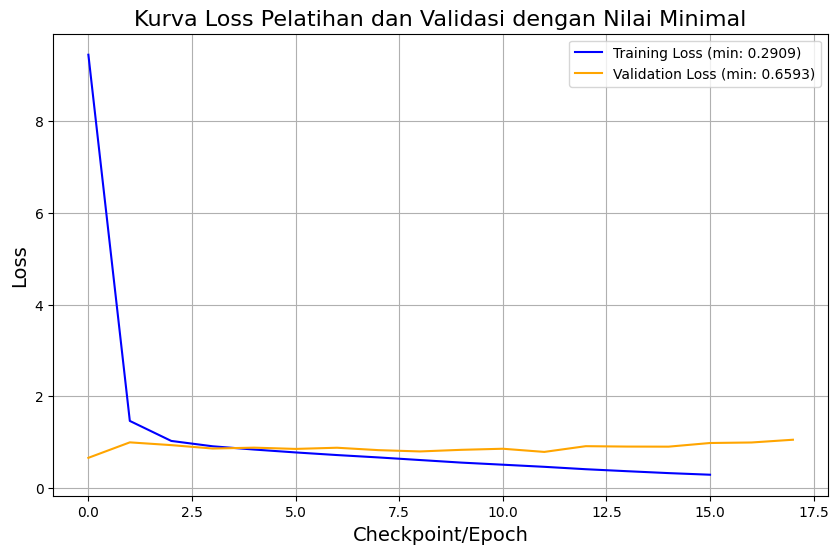

In [24]:
# Plot Kurva Loss Pelatihan dan Validasi
plot_loss_curves(training_loss_history, validation_loss_history)

# Evaluate Model

## Evaluation Metrics Score

In [25]:
# Evaluasi Model pada Test Dataset
ground_truths, predictions, bleu_score, rouge_score, ter_score = test_translation_model_evaluation(
    model=model, 
    tokenizer=tokenizer, 
    test_dataset=test_dataset, 
    batch_size=BATCH_SIZE
)

Testing: 13it [00:01, 11.94it/s]


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


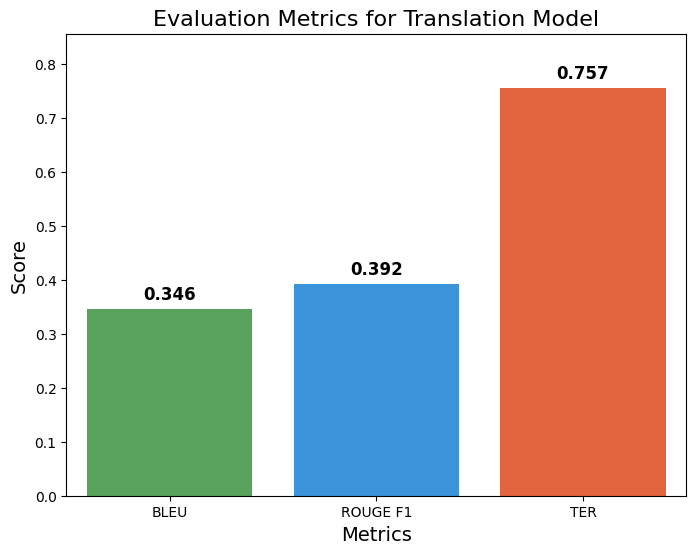

In [26]:
# Visualisasikan Metrik Evaluasi
plot_evaluation_metrics_visualization(bleu_score, rouge_score, ter_score)

## Target and Predicted

In [27]:
# Tampilkan Contoh Hasil Terjemahan
show_translation_examples(ground_truths, predictions, tokenizer, num_examples=20)


--- Menampilkan 20 Contoh Hasil Terjemahan ---

Hasil 1:
Target    : aku bermain tenis sepulang sekolah
Prediksi  : aku bemelmain tenis seureukolah
--------------------------------------------------
Hasil 2:
Target    : ko galak ampus kina
Prediksi  : ko ak perpus ka
--------------------------------------------------
Hasil 3:
Target    : apa ini milikmu
Prediksi  :  kaui wakku
--------------------------------------------------
Hasil 4:
Target    : mengapa kamu mengatakan itu
Prediksi  : gapa u ga  u
--------------------------------------------------
Hasil 5:
Target    : benei kh yek tom
Prediksi  : kai tokao keem
--------------------------------------------------
Hasil 6:
Target    : ken pun bo
Prediksi  : ken y
--------------------------------------------------
Hasil 7:
Target    : kaja ken anam
Prediksi  : k ks ak
--------------------------------------------------
Hasil 8:
Target    : adikku suka musik
Prediksi  : tdku suka musik
--------------------------------------------------
Ha

## Test Model With Input

In [28]:
# Contoh Teks Input untuk Translasi
input_text_example = "Ani ko serius muah laba ngen?"
source_lang = 'day'  # Bahasa sumber
target_lang = 'ind'  # Bahasa target

# Lakukan Translasi
translated_output = translate_input_text(
    input_text=input_text_example,
    source_language=source_lang,
    target_language=target_lang,
    tokenizer=tokenizer,
    model=model,
    max_length=MAX_SEQUENCE_LENGTH,
    language_token_map=LANGUAGE_TOKEN_MAP
)

print(f"Input ({source_lang}): {input_text_example}")
print(f"Terjemahan ({target_lang}): {translated_output}")

Input (day): Ani ko serius muah laba ngen?
Terjemahan (ind): serius muah laba ngen


Terjemahan Asli :  Apa kau serius mengatakannya?